# Stock Return Predictor
## Notebook 3: Modeling

**Project:** Predicting whether a stock will outperform the S&P 500 over the next month  
**Author:** Your Name  
**Date:** April 2026  

---

### Objective
Train and evaluate multiple classification models to predict whether a stock will 
outperform SPY the following month. We compare Logistic Regression, Ridge Classifier, 
and XGBoost, evaluating each on accuracy, AUC-ROC, and feature importance.

### Contents
1. Imports & Setup
2. Load Feature Data
3. Prepare Model Inputs
4. Train/Test Split
5. Logistic Regression
6. Ridge Classifier
7. XGBoost
8. Model Comparison
9. Feature Importance

## 1. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, 
                             classification_report, RocCurveDisplay)
from xgboost import XGBClassifier

## 2. Load Feature Data

In [2]:
DATA_DIR = "../data"

combined_df = pd.read_csv(f"{DATA_DIR}/features.csv", index_col=0, parse_dates=True)
print(f"Loaded features — shape: {combined_df.shape}")
combined_df.head()

Loaded features — shape: (77, 140)


,AAPL_ret_1m,AAPL_ret_3m,AAPL_ret_6m,AAPL_ma_ratio_20,AAPL_ma_ratio_50,AAPL_volatility,ABT_ret_1m,ABT_ret_3m,ABT_ret_6m,ABT_ma_ratio_20,...,JNJ_target,JPM_target,META_target,MRK_target,MSFT_target,PFE_target,SLB_target,UNH_target,WFC_target,XOM_target
date,,,,,,,,,,,,,,,,,,,,,
2018-07-31,0.016615,0.081859,0.145569,-0.000934,0.005789,0.152962,0.079256,0.138022,0.064213,0.034452,...,0,0,0,1,1,1,0,1,0,0
2018-08-31,0.098266,0.181668,0.297952,0.061912,0.139644,0.121025,0.024682,0.065214,0.108141,0.024752,...,1,0,0,1,1,1,0,0,0,1
2018-09-30,0.003155,0.210234,0.350468,0.015239,0.059595,0.225772,0.094598,0.208028,0.254991,0.067590,...,1,1,0,1,1,1,0,1,1,1
2018-10-31,-0.056923,0.055953,0.199339,-0.003106,-0.010474,0.344657,-0.039097,0.061221,0.183769,-0.000563,...,1,1,0,1,1,1,0,1,1,0
2018-11-30,-0.193578,-0.215260,-0.069724,-0.057841,-0.141543,0.444800,0.055595,0.107949,0.184970,0.045225,...,0,0,1,1,1,1,0,0,0,0


## 3. Prepare Model Inputs
We stack the data so each row is one stock in one month (long format),
with its features as inputs and its target as the label.

In [3]:
TICKERS = [
    "AAPL", "MSFT", "GOOGL", "AMZN", "META",
    "JPM", "GS", "BAC", "WFC", "C",
    "XOM", "CVX", "COP", "SLB", "EOG",
    "JNJ", "PFE", "UNH", "MRK", "ABT"
]

FEATURE_COLS = ["ret_1m", "ret_3m", "ret_6m", "ma_ratio_20", "ma_ratio_50", "volatility"]

rows = []
for ticker in TICKERS:
    feature_names = [f"{ticker}_{f}" for f in FEATURE_COLS]
    target_name = f"{ticker}_target"
    
    if not all(c in combined_df.columns for c in feature_names + [target_name]):
        continue
    
    temp = combined_df[feature_names + [target_name]].copy()
    temp.columns = FEATURE_COLS + ["target"]
    temp["ticker"] = ticker
    rows.append(temp)

model_df = pd.concat(rows).sort_index()
print(f"Model dataframe shape: {model_df.shape}")
print(f"Target distribution:\n{model_df['target'].value_counts()}")
model_df.head()

Model dataframe shape: (1540, 8)
Target distribution:
target
0    817
1    723
Name: count, dtype: int64


,ret_1m,ret_3m,ret_6m,ma_ratio_20,ma_ratio_50,volatility,target,ticker
date,,,,,,,,
2018-07-31,0.016615,0.081859,0.145569,-0.000934,0.005789,0.152962,1,AAPL
2018-07-31,0.035424,-0.009433,-0.069145,0.006792,-0.003427,0.168784,0,SLB
2018-07-31,0.056515,0.111771,0.243956,0.022337,0.047725,0.189843,0,COP
2018-07-31,0.074520,0.196063,0.038064,0.019098,0.057536,0.254946,0,GOOGL
2018-07-31,0.060694,0.139341,0.126621,0.011538,0.040931,0.213713,1,MSFT


## 4. Train/Test Split
We split by time — never randomly — to avoid data leakage.
Training on 80% of dates, testing on the most recent 20%.

In [4]:
dates = model_df.index.unique().sort_values()
split_idx = int(len(dates) * 0.8)
split_date = dates[split_idx]
print(f"Train: up to {split_date.date()}")
print(f"Test:  {split_date.date()} onwards")

train_df = model_df[model_df.index < split_date]
test_df  = model_df[model_df.index >= split_date]

X_train = train_df[FEATURE_COLS]
y_train = train_df["target"]
X_test  = test_df[FEATURE_COLS]
y_test  = test_df["target"]

print(f"\nTrain size: {X_train.shape}, Test size: {X_test.shape}")

Train: up to 2023-08-31
Test:  2023-08-31 onwards

Train size: (1220, 6), Test size: (320, 6)


In [5]:
# Scale features — important for logistic regression and ridge
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

## 5. Logistic Regression
Simple, interpretable baseline model.

In [6]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

lr_preds = lr.predict(X_test_scaled)
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]

lr_acc = accuracy_score(y_test, lr_preds)
lr_auc = roc_auc_score(y_test, lr_probs)

print(f"Logistic Regression — Accuracy: {lr_acc:.3f} | AUC: {lr_auc:.3f}")
print(classification_report(y_test, lr_preds))

Logistic Regression — Accuracy: 0.519 | AUC: 0.470
              precision    recall  f1-score   support

           0       0.53      0.76      0.63       170
           1       0.47      0.25      0.32       150

    accuracy                           0.52       320
   macro avg       0.50      0.50      0.48       320
weighted avg       0.51      0.52      0.48       320



## 6. Ridge Classifier
Handles multicollinearity well — good when features are correlated.

In [7]:
ridge = RidgeClassifier(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

ridge_preds = ridge.predict(X_test_scaled)

ridge_acc = accuracy_score(y_test, ridge_preds)

print(f"Ridge Classifier — Accuracy: {ridge_acc:.3f}")
print(classification_report(y_test, ridge_preds))

Ridge Classifier — Accuracy: 0.525
              precision    recall  f1-score   support

           0       0.54      0.77      0.63       170
           1       0.49      0.25      0.33       150

    accuracy                           0.53       320
   macro avg       0.51      0.51      0.48       320
weighted avg       0.51      0.53      0.49       320



## 7. XGBoost
Gradient boosted trees — captures non-linear relationships between features.

In [8]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss",
    verbosity=0
)
xgb.fit(X_train_scaled, y_train)

xgb_preds = xgb.predict(X_test_scaled)
xgb_probs = xgb.predict_proba(X_test_scaled)[:, 1]

xgb_acc = accuracy_score(y_test, xgb_preds)
xgb_auc = roc_auc_score(y_test, xgb_probs)

print(f"XGBoost — Accuracy: {xgb_acc:.3f} | AUC: {xgb_auc:.3f}")
print(classification_report(y_test, xgb_preds))

XGBoost — Accuracy: 0.500 | AUC: 0.493
              precision    recall  f1-score   support

           0       0.52      0.62      0.57       170
           1       0.46      0.36      0.40       150

    accuracy                           0.50       320
   macro avg       0.49      0.49      0.49       320
weighted avg       0.49      0.50      0.49       320



## 8. Model Comparison

              Model  Accuracy      AUC
Logistic Regression   0.51875 0.470196
   Ridge Classifier   0.52500      NaN
            XGBoost   0.50000 0.492588


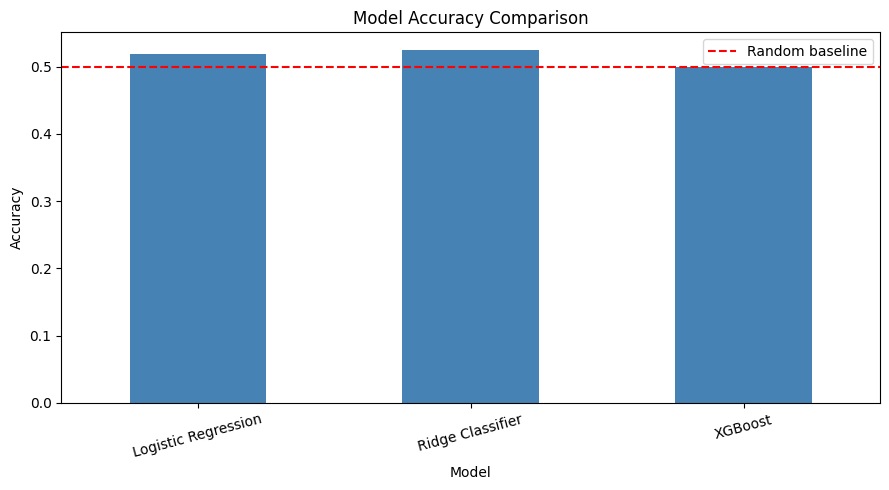

In [9]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Ridge Classifier", "XGBoost"],
    "Accuracy": [lr_acc, ridge_acc, xgb_acc],
    "AUC":      [lr_auc, None, xgb_auc]
})

print(results.to_string(index=False))

# Bar chart
results_plot = results[["Model", "Accuracy"]].set_index("Model")
results_plot.plot(kind="bar", figsize=(9, 5), legend=False, 
                  title="Model Accuracy Comparison", color="steelblue")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.axhline(0.5, color="red", linestyle="--", label="Random baseline")
plt.legend(["Random baseline"])
plt.tight_layout()
plt.show()

## 9. Feature Importance
Which features does XGBoost rely on most?

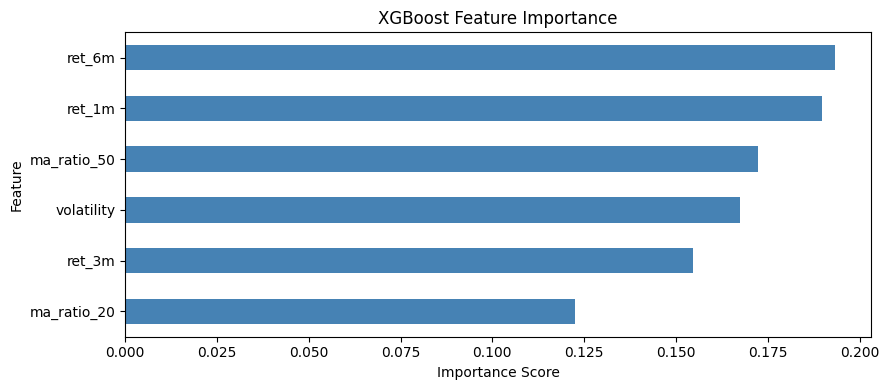

In [10]:
importance_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=True)

importance_df.plot(kind="barh", x="Feature", y="Importance", 
                   figsize=(9, 4), legend=False,
                   title="XGBoost Feature Importance", color="steelblue")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()